# Trabajo final de Estadística Aplicada
Copia curada del notebook académico de Paola Tucuman. Las preguntas 1–8 fueron parte de la consigna del curso; las secciones ANÁLISIS EXTRA documentan la exploración adicional. Se retiró el código de estudiante y se conservó solo la salida del gráfico destacado. Esta copia también aclara interpretaciones y corrige la celda del gráfico para poder ejecutarla desde la raíz del repositorio.

In [ ]:
import pandas as pd

##### 1. Carga el dataset de tu número de grupo de la carpeta base de datos de Moodle.

In [ ]:
data = pd.read_csv('data/RetailNuevo3.csv')
data.info()
data.head()

##### 2. Expresa las ventas segmentadas por estado, por modo de entrega (Ship Mode) y por subcategoría.

In [ ]:
# Ventas por estado

ventas_por_estado = data.groupby('State')['Sales'].sum()
print(ventas_por_estado)

In [ ]:
# Ventas por modo de entrega

ventas_por_ship_mode = data.groupby('Ship Mode')['Sales'].sum()
print(ventas_por_ship_mode)


In [ ]:
# Ventas por subcategoría

ventas_por_subcategoria = data.groupby('Sub-Category')['Sales'].sum()
print(ventas_por_subcategoria)

##### 3. Por cada categoría haga un diagrama de torta que exprese el porcentaje de ventas de cada subcategoría. 

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
categorias = data['Category'].unique()
for categoria in categorias:
    subcategorias = data[data['Category'] == categoria].groupby('Sub-Category')['Sales'].sum()

    plt.figure(figsize=(8, 6))
    plt.pie(subcategorias, labels=subcategorias.index, autopct='%1.2f%%')
    plt.title(f'Porcentaje de Ventas por Subcategoría en {categoria}')
    plt.show()

##### 4. Da un intervalo de confianza para la media de ventas de la tienda principal (la de mayor venta) al 90% y al 98% de confiabilidad. Si consideramos que se van a realizar 500 ventas en dicha tienda da una estimación de cuanto podemos ganar en dicha tienda a las mismas confiabilidades que hemos considerado en el punto anterior. 

In [ ]:
import numpy as np
from scipy.stats import norm

In [ ]:
# Identificar la tienda principal (la de mayor venta por ciudad)
ventas_por_ciudad = data.groupby('City')['Sales'].sum()
tienda_principal = ventas_por_ciudad.idxmax()
ventas_tienda_principal = data[data['City'] == tienda_principal]['Sales']

media = sum(ventas_tienda_principal)/len(ventas_tienda_principal)
desv = np.std(ventas_tienda_principal, ddof=1)
n = len(ventas_tienda_principal)


In [ ]:
# Intervalo de confianza al 90% y 98%
confianza = [0.90, 0.98]
for conf in confianza:
    z = norm.ppf((1 + conf) / 2)
    margen_error = z * (desv / np.sqrt(n))
    intervalo = (media - margen_error, media + margen_error)
    intervalo1 = (media - margen_error)
    intervalo2 = (media + margen_error)
    print(f'Intervalo de confianza al {conf*100}%: {intervalo1:.2f} a {intervalo2:.2f}')
    
    # Estimación de ganancias para 500 ventas
    estimacion_ganancia = 500 * media
    print(f'Estimación de ganancia con 500 ventas al {conf*100}%: {estimacion_ganancia:.2f}')

##### 5. Verifica si estadísticamente los siguientes estados tienen las mismas ventas. 
###### (a) Washington y Arkansas. 
###### (b) Arkansas y Maryland. 
###### (c) Minnesota y Montana 
###### (d) South Carolina y Connecticut 

In [ ]:
from scipy.stats import ttest_ind

In [ ]:
# Comparaciones de ventas por estados
pares_estados = [('Washington', 'Arkansas'),
                 ('Arkansas', 'Maryland'),
                 ('Minnesota', 'Montana'),
                 ('South Carolina', 'Connecticut')]

for estado1, estado2 in pares_estados:
    ventas1 = data[data['State'] == estado1]['Sales']
    ventas2 = data[data['State'] == estado2]['Sales']

    stat, p_value = ttest_ind(ventas1, ventas2, equal_var=False)

    print(f'Comparación {estado1} vs {estado2}: p-value = {p_value:.4f}')
    
    if p_value < 0.05:
        print('Rechazamos la hipótesis nula: Hay diferencia significativa.')
    else:
        print('No se rechaza la hipótesis nula: No hay diferencia significativa.')

##### 6. Verifica si estadísticamente las siguientes subcategorías tienen las mismas ventas: 
###### (a) Accessories y Phones. 
###### (b) Art y Envelopes. 
###### (c) Paper y Storage. 

In [ ]:
# Comparaciones de ventas por subcategorías
pares_subcategorias = [('Accessories', 'Phones'),
                       ('Art', 'Envelopes'),
                       ('Paper', 'Storage')]

for sub1, sub2 in pares_subcategorias:
    ventas1 = data[data['Sub-Category'] == sub1]['Sales']
    ventas2 = data[data['Sub-Category'] == sub2]['Sales']

    stat, p_value = ttest_ind(ventas1, ventas2, equal_var=False)

    print(f'Comparación {sub1} vs {sub2}: p-value = {p_value:.4f}')
    
    if p_value < 0.05:
        print('Rechazamos la hipótesis nula: Hay diferencia significativa.')
    else:
        print('No se rechaza la hipótesis nula: No hay diferencia significativa.')

##### 7. En función de lo observado hacer comparaciones adicionales que considere pertinentes. 
##### ANALISIS EXTRA 1: ¿Que tan rentable es cada categoria y subcategoria?

In [ ]:
# Podria ser interesante analizar el margen de ganancia por categoría y subcategoría
margen_por_categoria = data.groupby('Category')[['Sales', 'Profit']].sum()
margen_por_categoria['Profit Margin'] = margen_por_categoria['Profit'] / margen_por_categoria['Sales'] * 100

margen_por_subcategoria = data.groupby('Sub-Category')[['Sales', 'Profit']].sum()
margen_por_subcategoria['Profit Margin'] = margen_por_subcategoria['Profit'] / margen_por_subcategoria['Sales'] * 100

print("Margen de Ganancia por Categoría:\n", margen_por_categoria)
print("\nMargen de Ganancia por Subcategoría:\n", margen_por_subcategoria)

##### ANALISIS EXTRA 1.1: Como se observa en las subcategorias existen margenes negativos, lo cual se debe a las perdidas en determinadas subcategorias como se muestra a continuacion:

In [ ]:
# Identificar valores con márgenes de ganancia negativos en subcategorías
subcategorias_negativas = margen_por_subcategoria[margen_por_subcategoria['Profit Margin'] < 0]
print("\nSubcategorías con Márgenes de Ganancia Negativos:\n", subcategorias_negativas)

# Crear listas de nombres de categorías y subcategorías con márgenes negativos
lista_subcategorias_negativas = subcategorias_negativas.index.tolist()

print("Las Subcategorías con Márgenes Negativos son:", lista_subcategorias_negativas)

##### ANALISIS EXTRA 2: ¿Existe relacion ente los descuentos ofrecidos y las ganancias?

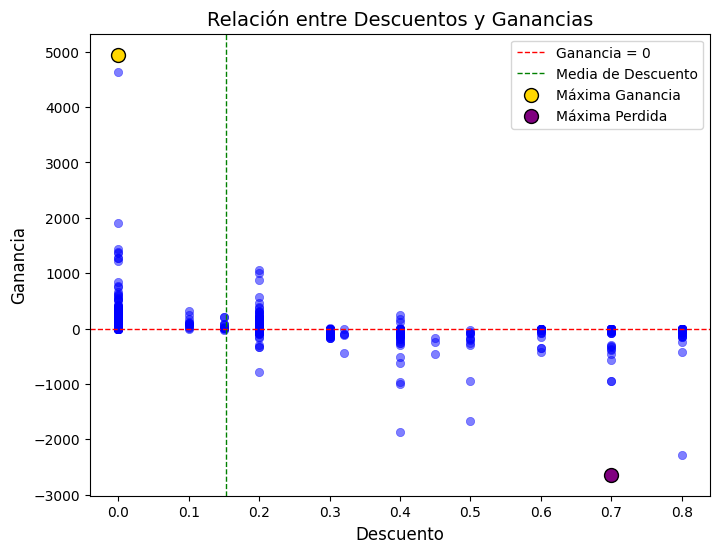

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.scatterplot(x=data['Discount'], y=data['Profit'], alpha=0.5, color='blue', edgecolor=None)

plt.axhline(0, color='red', linestyle='--', linewidth=1, label='Ganancia = 0')
plt.axvline(data['Discount'].mean(), color='green', linestyle='--', linewidth=1, label='Media de Descuento')
plt.title('Relación entre Descuentos y Ganancias', fontsize=14)
plt.xlabel('Descuento', fontsize=12)
plt.ylabel('Ganancia', fontsize=12)

max_profit_idx = data['Profit'].idxmax()
min_profit_idx = data['Profit'].idxmin()

plt.scatter(data.loc[max_profit_idx, 'Discount'], data.loc[max_profit_idx, 'Profit'], 
            color='gold', s=100, label='Máxima Ganancia', edgecolor='black')
plt.scatter(data.loc[min_profit_idx, 'Discount'], data.loc[min_profit_idx, 'Profit'], 
            color='purple', s=100, label='Máxima Perdida', edgecolor='black')

plt.legend()

correlacion_descuento_ganancia = data[['Discount', 'Profit']].corr()
print('Correlación entre Descuento y Ganancia:', correlacion_descuento_ganancia)
plt.show()

El gráfico muestra la dispersión de ganancias por nivel de descuento. Los puntos amarillo y morado son las transacciones con mayor ganancia y mayor pérdida; por sí solos no muestran una tendencia ni prueban que el descuento haya causado esos resultados. La correlación resume una asociación del conjunto, no un efecto causal.

### ANÁLISIS EXTRA 3: Comparación de ventas por estado

In [ ]:
ventas_por_estado = data.groupby('State')['Sales'].sum().sort_values(ascending=False)

top_10_mayores_ventas = ventas_por_estado.head(5)
top_10_menores_ventas = ventas_por_estado.tail(5)

plt.figure(figsize=(10, 5))
ax1 = top_10_mayores_ventas.plot(kind='bar', color='green', alpha=0.8)
plt.title('Top 5 Estados con Mayores Ventas', fontsize=14)
plt.xlabel('Estado', fontsize=12)
plt.ylabel('Ventas Totales', fontsize=12)
plt.xticks(rotation=45)

for index, value in enumerate(top_10_mayores_ventas):
    ax1.text(index, value + max(top_10_mayores_ventas) * 0.01, f'{value:.0f}', ha='center', fontsize=10)

plt.figure(figsize=(10, 5))
ax2 = top_10_menores_ventas.plot(kind='bar', color='red', alpha=0.8)
plt.title('Top 5 Estados con Menores Ventas', fontsize=14)
plt.xlabel('Estado', fontsize=12)
plt.ylabel('Ventas Totales', fontsize=12)
plt.xticks(rotation=45)

for index, value in enumerate(top_10_menores_ventas):
    ax2.text(index, value + max(top_10_menores_ventas) * 0.01, f'{value:.0f}', ha='center', fontsize=10)


##### 8. Da recomendaciones en función de lo que analizó para poner mayor énfasis de marketing en las áreas donde tenemos mejores ventas

## Recomendaciones revisadas para el portafolio

- Revisar primero costos, precios y descuentos de las subcategorías con pérdida neta antes de decidir cambios de promociones.
- Explorar por qué algunas regiones tienen menos ventas antes de asignar recursos de marketing; el total observado no mide por sí solo el potencial de cada mercado.
- Analizar los descuentos dentro de cada subcategoría y controlar otros factores. La asociación observada no demuestra que reducir descuentos aumente la ganancia.

Estas recomendaciones son hipótesis para investigar con más información sobre periodo, clientes, costos y estrategia comercial; el CSV de clase no documenta esos factores.